# 1. Segunda Verificação Parcial: Deep Learning (CNN e RNN)
**Disciplina:** Aprendizado de Máquina – PPGEP/UFPE | **Prof.:** Márcio das Chagas Moura
**Discente:** <Isac Souto> | **Semestre:** 2026.2 | **Entrega:** 28/10/2026

## Objetivo
Aplicar CNN e RNN a problemas industriais:
- **Parte A (CNN):** classificação de defeitos em 2 datasets, comparando a CNN com MLP, SVM, AD, RF e NB.
- **Parte B (RNN):** estimação da Vida Útil Remanescente (RUL) de motores turbofan (C-MAPSS FD001).

## 1.2 Escolha do Dataset (Parte A)

Escolhi o **Dataset 1 (PCB Defect)**

| | PCB Defect |
|---|---|
| Aplicação | Inspeção óptica (AOI) de placas de circuito |
| Imagens / classes | 1.386 / 6 defeitos |
| Balanceamento | Balanceado |
| Desafio | Defeitos minúsculos em imagem de alta resolução |
| Pré-processamento | 128×128 + HOG |

### Justificativa
1. **Relevância para Engenharia de Produção:** é um problema real de controle de qualidade em linha de produção.
2. **Cenários complementares:** um caso balanceado (PCB).
3. **Desafios visuais diferentes:** objetos pequenos e de alta resolução (PCB) Isso testa a capacidade da CNN de aprender features automaticamente frente ao HOG/flatten usados nos modelos clássicos.
4. **Continuidade:** o PCB já foi trabalhado na 1ª verificação, o que permite comparar a CNN com os resultados clássicos anteriores.

### Hipóteses
- A CNN deve superar os modelos clássicos no PCB (defeitos pequenos e padrões espaciais).


## Instalação e Configuração de Bibliotecas

Nesta seção, instalamos e configuramos as bibliotecas necessárias para o projeto, incluindo `scikeras` para integrar Keras com Scikit-learn e ajustamos a versão do `scikit-learn` para compatibilidade.

In [ ]:
pip install scikeras

In [ ]:
# Instalação do Optuna no topo do notebook, junto às outras instalações
!pip install optuna -q

In [ ]:
pip install "scikit-learn<1.6.0"

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 13.0/13.0 MB 42.9 MB/s  0:00:00
  Attempting uninstall: scikit-learn
    Found existing installation: scikit-learn 1.6.1
    Uninstalling scikit-learn-1.6.1:
      Successfully uninstalled scikit-learn-1.6.1
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
hdbscan 0.8.44 requires scikit-learn>=1.6, but you have scikit-learn 1.5.2 which is incompatible.
umap-learn 0.5.12 requires scikit-learn>=1.6, but you have scikit-learn 1.5.2 which is incompatible.


In [ ]:
import random

import cv2

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import kagglehub
import glob
import os
from skimage.feature import hog
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split

from scikeras.wrappers import KerasClassifier


import time
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.utils import plot_model
from tensorflow.keras.callbacks import EarlyStopping


from sklearn.model_selection import GridSearchCV
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix

In [ ]:
# Importação do Optuna e configuração de supressão de logs
import optuna
optuna.logging.set_verbosity(optuna.logging.WARNING)

## Análise Exploratória dos Dados (EDA)

### Download e Consolidação de Rótulos
Esta primeira parte do código é responsável por baixar o conjunto de dados do Kaggle, listar todos os arquivos de imagem e criar um DataFrame do Pandas. Cada linha no DataFrame representa uma imagem, com seu caminho e a classe de defeito associada. Além disso, o rotation foi "tirado", juntando tudo para 6 classes.

In [ ]:
# Download do conjunto de dados do Kaggle e obtenção dos caminhos das imagens
path = kagglehub.dataset_download("akhatova/pcb-defects")
arquivos = glob.glob(os.path.join(path, '**', '*.jpg'), recursive=True)

# Criação de um DataFrame com os caminhos e extração da classe de cada imagem
df = pd.DataFrame({'caminho': arquivos})
df['classe'] = df['caminho'].apply(lambda x: os.path.basename(os.path.dirname(x)).replace('_rotation', ''))

Using Colab cache for faster access to the 'pcb-defects' dataset.


## Pré-processamento Detalhado e Engenharia de Atributos (HOG)

Nesta etapa crucial, os dados são preparados para o treinamento do modelo. Inclui a extração de recortes de defeitos dos arquivos XML, divisão dos dados em conjuntos de treino, validação e teste, codificação das classes e extração de atributos HOG, seguidos por sua normalização.

### *Imports e caminhos base*

In [ ]:
import os
import glob
import cv2
import numpy as np
import pandas as pd
import seaborn as sns
import xml.etree.ElementTree as ET
from skimage.feature import hog
from sklearn.model_selection import GroupShuffleSplit
from sklearn.preprocessing import StandardScaler

base = os.path.join(path, "PCB_DATASET")
pasta_imagens = os.path.join(base, "images")
pasta_anotacoes = os.path.join(base, "Annotations")


# Define onde estão as imagens (pasta 'images', organizada em subpastas por
# classe) e onde estão as anotações XML (pasta 'Annotations', com a mesma
# organização por classe). São duas árvores de pastas paralelas: pra cada
# imagem em 'images/<classe>/', existe um XML correspondente em
# 'Annotations/<classe>/' com o mesmo nome (trocando .jpg por .xml).

DIMENSAO_RECORTE = (64, 64) #variavel constante

# Tamanho final que cada recorte de defeito terá depois de redimensionado.
# 64x64 foi escolhido porque a mediana do tamanho real dos bounding boxes
# ficou bem abaixo de 128px — usar 128 forçaria muito o aumento das dimensões
# ou resolução das imagens
# (esticar uma região pequena, gerando borrão/interpolação excessiva).

MARGEM = 15

# Quantos pixels de "contexto" adicionar ao redor do bounding box do defeito.
# Sem margem, o recorte pega só o defeito "cru", sem nada ao redor pra
# comparar. Com margem, o modelo pode
# aprender o contraste entre "como deveria ser" (contexto) e "o que está
# errado" (o defeito no centro).


### *Montagem do DataFrame de recortes*

In [ ]:
registros = []

# Percorre cada pasta de classe dentro de 'images/' (ex: 'Mouse_bite', 'Spur'...)

for classe in os.listdir(pasta_imagens):
    pasta_classe_ann = os.path.join(pasta_anotacoes, classe)
    if not os.path.isdir(pasta_classe_ann):
        continue

    for arquivo_xml in glob.glob(os.path.join(pasta_classe_ann, "*.xml")):
        root = ET.parse(arquivo_xml).getroot()
        nome_arquivo_imagem = root.find('filename').text
        caminho_imagem = os.path.join(pasta_imagens, classe, nome_arquivo_imagem)

        if not os.path.exists(caminho_imagem):
            continue


        for obj in root.findall('object'):
            nome_classe = obj.find('name').text.strip().lower() # aqui ta buscando em letras minúsculas
            bbox = obj.find('bndbox')
            registros.append({
                'caminho_imagem': caminho_imagem,
                'classe': nome_classe,
                'xmin': int(bbox.find('xmin').text),
                'ymin': int(bbox.find('ymin').text),
                'xmax': int(bbox.find('xmax').text),
                'ymax': int(bbox.find('ymax').text),
                'imagem_origem': nome_arquivo_imagem,
            })


# reset_index garante que as posições do DataFrame (0, 1, 2...) fiquem
# alinhadas com as posições dos arrays de imagens/features.
# Além disso, a lista é transformada em um DF, onde cada linha é um
# defeito individual.
df_recortes = pd.DataFrame(registros).reset_index(drop=True)

print("Total de recortes (defeitos):", df_recortes.shape[0])

Total de recortes (defeitos): 2953


### *Divisão de Imagens do Dataset (apenas para nível de entendimento)*

In [ ]:
pasta_rotacao = os.path.join(base, "rotation")

qtd_normais = df_recortes['imagem_origem'].nunique()
qtd_rotacionadas = len(glob.glob(os.path.join(pasta_rotacao, '**', '*.jpg'), recursive=True))

print(f"Imagens em posição normal: {qtd_normais}")
print(f"Imagens rotacionadas:      {qtd_rotacionadas}")
print(f"Total de imagens:          {qtd_normais + qtd_rotacionadas}")
print(f"Total de recortes (defeitos) extraídos: {df_recortes.shape[0]}")

Imagens em posição normal: 693
Imagens rotacionadas:      693
Total de imagens:          1386
Total de recortes (defeitos) extraídos: 2953


### *Codificação das classes + tradução*

In [ ]:
classes = sorted(df_recortes['classe'].unique())
num_classes = len(classes)
class_to_idx = {cls: idx for idx, cls in enumerate(classes)}

class_translations = {
    'missing_hole': 'Buraco Ausente',
    'mouse_bite': 'Mordida de Rato',
    'open_circuit': 'Circuito Aberto',
    'short': 'Curto-circuito',
    'spur': 'Esporão',
    'spurious_copper': 'Cobre Espúrio'
}

idx_to_class = {idx: class_translations.get(cls, cls) for cls, idx in class_to_idx.items()}

print("Classes (traduzidas):")
for idx, class_name in idx_to_class.items():
    print(f"{idx}: {class_name}")
print(f"Número de classes: {num_classes}")

Classes (traduzidas):
0: Buraco Ausente
1: Mordida de Rato
2: Circuito Aberto
3: Curto-circuito
4: Esporão
5: Cobre Espúrio
Número de classes: 6


### *Distribuição das classes (Imagens)*

Distribuição das imagens originais por classe:
classe
Short              232
Open_circuit       232
Spurious_copper    232
Mouse_bite         230
Spur               230
Missing_hole       230
Name: count, dtype: int64


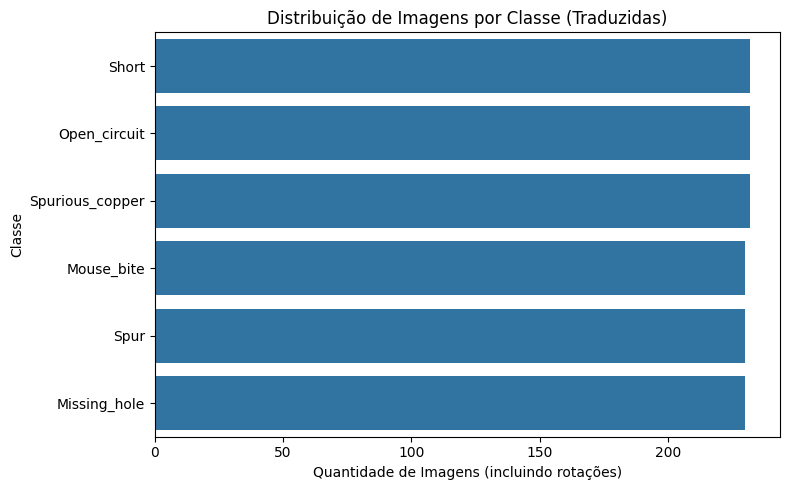

In [ ]:
print("Distribuição das imagens originais por classe:")
contagem_imagens = df['classe'].value_counts()
print(contagem_imagens)

plt.figure(figsize=(8, 5))
sns.countplot(data=df, y='classe', order=contagem_imagens.index)
plt.title('Distribuição de Imagens por Classe (Traduzidas)')
plt.xlabel('Quantidade de Imagens (incluindo rotações)')
plt.ylabel('Classe')
plt.tight_layout()
plt.show()

### *Distribuição das classes (apenas de defeitos)*

Distribuição das classes (contagem de recortes por classe):
classe
spurious_copper    503
missing_hole       497
mouse_bite         492
short              491
spur               488
open_circuit       482
Name: count, dtype: int64


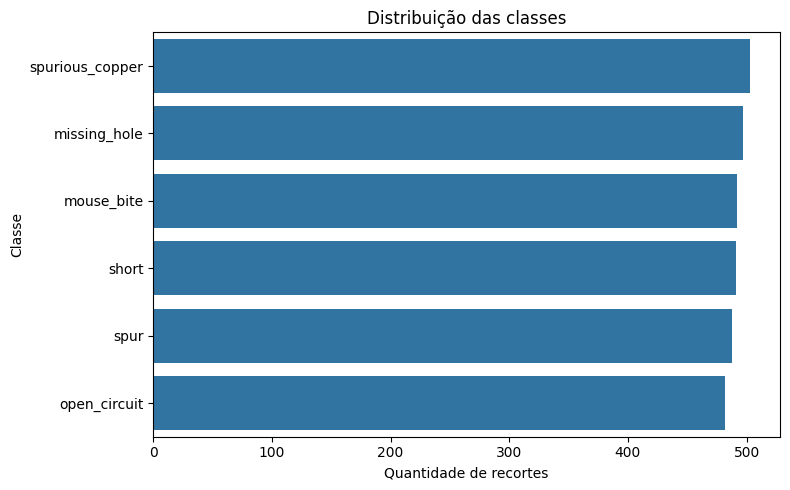

In [ ]:
print("Distribuição das classes (contagem de recortes por classe):")
print(df_recortes['classe'].value_counts())

plt.figure(figsize=(8, 5))
sns.countplot(data=df_recortes, y='classe', order=df_recortes['classe'].value_counts().index)
plt.title('Distribuição das classes')
plt.xlabel('Quantidade de recortes')
plt.ylabel('Classe')
plt.tight_layout()
plt.show()

### *Verificação de desbalanceamento*

In [ ]:
contagem = df_recortes['classe'].value_counts()
proporcao = contagem / contagem.sum() * 100

print("Proporção de cada classe (%):")
print(proporcao.round(2))

razao_desbalanceamento = contagem.max() / contagem.min()
print(f"\nRazão entre a classe mais frequente e a menos frequente: {razao_desbalanceamento:.2f}x")
print(f"Classe mais frequente: {contagem.idxmax()} ({contagem.max()} recortes)")
print(f"Classe menos frequente: {contagem.idxmin()} ({contagem.min()} recortes)")

Proporção de cada classe (%):
classe
spurious_copper    17.03
missing_hole       16.83
mouse_bite         16.66
short              16.63
spur               16.53
open_circuit       16.32
Name: count, dtype: float64

Razão entre a classe mais frequente e a menos frequente: 1.04x
Classe mais frequente: spurious_copper (503 recortes)
Classe menos frequente: open_circuit (482 recortes)


In [ ]:
def redimensionar_recortes(df, margem=MARGEM, dimensao=DIMENSAO_RECORTE):
    """Lê cada imagem do DataFrame, recorta a região do bounding box (+ margem)
    e redimensiona pro tamanho padrão. Retorna um array de imagens em escala
    de cinza, já no tamanho final — serve de base tanto pro caminho de pixels
    quanto pro caminho de HOG, evitando ler/recortar a imagem duas vezes."""
    imagens = []
    for _, linha in df.iterrows():
        img = cv2.imread(linha['caminho_imagem'], cv2.IMREAD_GRAYSCALE)
        h, w = img.shape
        x1 = max(0, linha['xmin'] - margem)
        y1 = max(0, linha['ymin'] - margem)
        x2 = min(w, linha['xmax'] + margem)
        y2 = min(h, linha['ymax'] + margem)
        recorte = img[y1:y2, x1:x2]
        recorte_resized = cv2.resize(recorte, dimensao)
        imagens.append(recorte_resized)
    return np.array(imagens)

# Aplicado em TODOS os recortes de uma vez — antes do split. Isso é seguro
# porque redimensionar não depende da distribuição dos dados, só do
# tamanho de cada imagem individual.
X_todas_img = redimensionar_recortes(df_recortes)
print("Shape das imagens redimensionadas:", X_todas_img.shape)

Shape das imagens redimensionadas: (2953, 64, 64)


### *Normalização de pixels*

In [ ]:

# 4. Normalização de Pixels (Mantida do seu código original)
X_todas_img_norm = X_todas_img.astype("float32") / 255.0

# Verifica se a imagem é RGB (3 canais) ou Tons de Cinza (1 canal)
# Se o seu X_todas_img_norm tiver shape (N, 128, 128), adicionamos a dimensão de canal
if len(X_todas_img_norm.shape) == 3:
    X_todas_cnn = np.expand_dims(X_todas_img_norm, axis=-1) # Vira (N, 128, 128, 1)
else:
    X_todas_cnn = X_todas_img_norm # Já é (N, 128, 128, 3)

print("Shape pronto para CNN:", X_todas_cnn.shape)

# 5. Split Treino/Teste usando StratifiedGroupKFold
from sklearn.model_selection import StratifiedGroupKFold
from tensorflow.keras.utils import to_categorical

sgkf = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)
idx_treino, idx_teste = next(sgkf.split(df_recortes, df_recortes['classe'], groups=df_recortes['imagem_origem']))

# Mapeando os arrays X diretamente para Treino e Teste no formato CNN
X_treino_cnn, X_teste_cnn = X_todas_cnn[idx_treino], X_todas_cnn[idx_teste]

# Mapeando e convertendo as labels (Y) para One-Hot Encoding
# Assumindo que você tem um dicionário 'class_to_idx' configurado
num_classes = 6
y_treino_idx = df_recortes.iloc[idx_treino]['classe'].map(class_to_idx).values
y_teste_idx = df_recortes.iloc[idx_teste]['classe'].map(class_to_idx).values

y_treino_ohe = to_categorical(y_treino_idx, num_classes)
y_teste_ohe = to_categorical(y_teste_idx, num_classes)

print("Treino CNN:", X_treino_cnn.shape, "| Teste CNN:", X_teste_cnn.shape)

Shape pronto para CNN: (2953, 64, 64, 1)
Treino CNN: (2363, 64, 64, 1) | Teste CNN: (590, 64, 64, 1)


```markdown
## Extração de Características usando HOG (Histogram of Oriented Gradients)

Conforme as diretrizes, em vez de um modelo híbrido, extraímos os vetores de características estruturais das imagens pré-processadas usando o algoritmo HOG para alimentar os modelos de Machine Learning clássicos.
```

In [ ]:
def extrair_hog_dataset(imagens):
    features_hog = []
    for img in imagens:
        # Extrai vetor HOG
        fd = hog(img, orientations=8, pixels_per_cell=(16, 16),
                 cells_per_block=(2, 2), visualize=False)
        features_hog.append(fd)
    return np.array(features_hog)

# Extrair HOG das imagens de treino e teste
X_treino_hog_raw = extrair_hog_dataset(X_treino_cnn.squeeze())
X_teste_hog_raw = extrair_hog_dataset(X_teste_cnn.squeeze())

# Padronizar as features HOG
scaler = StandardScaler()
X_treino_features = scaler.fit_transform(X_treino_hog_raw)
X_teste_features = scaler.transform(X_teste_hog_raw)

print("Shape dos atributos HOG de treino:", X_treino_features.shape)
print("Shape dos atributos HOG de teste:", X_teste_features.shape)

Shape dos atributos HOG de treino: (2363, 288)
Shape dos atributos HOG de teste: (590, 288)


## Visualização de Amostras de Imagens Originais

Este bloco de código exibe amostras de imagens de cada classe de defeito, conforme baixadas, permitindo uma inspeção visual inicial antes de qualquer pré-processamento mais aprofundado.

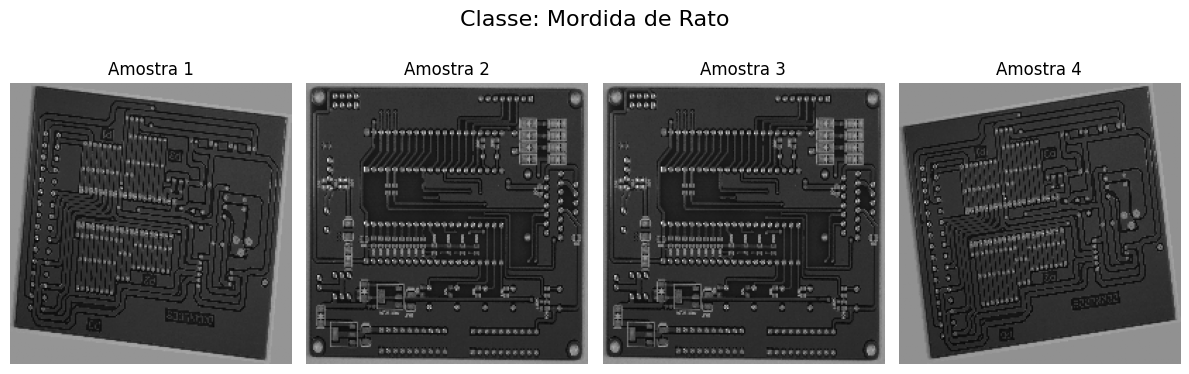

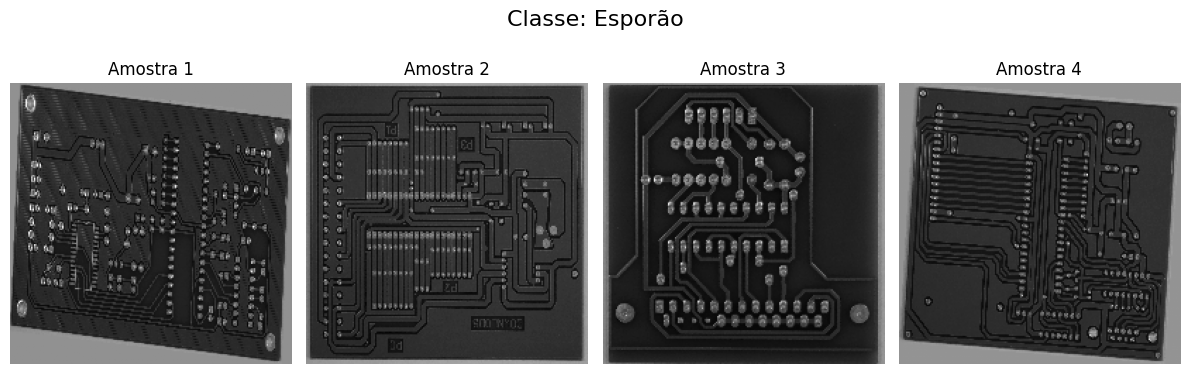

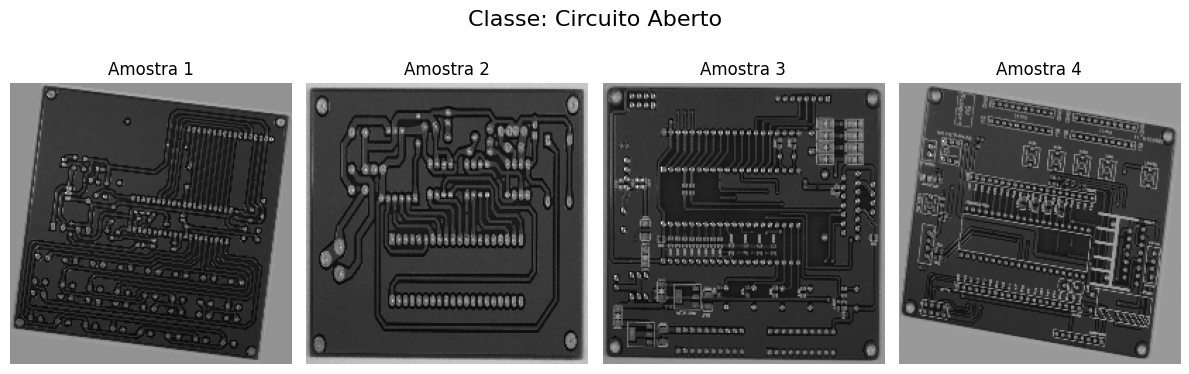

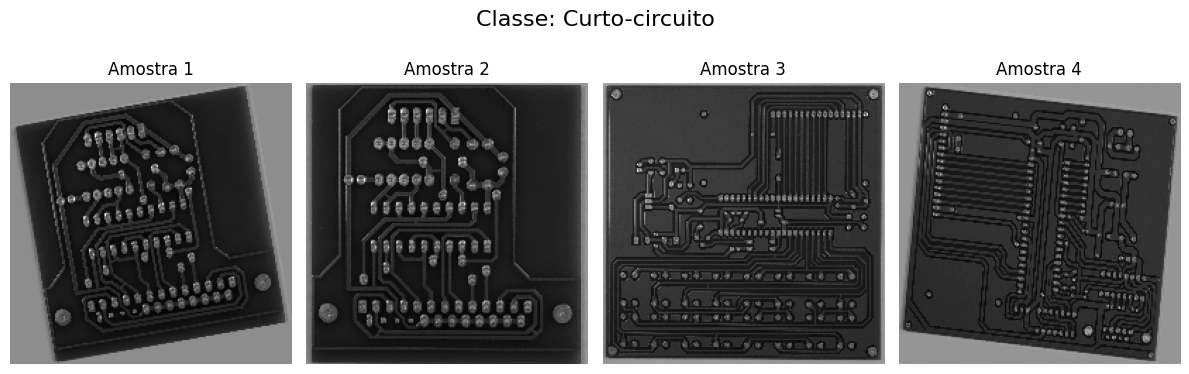

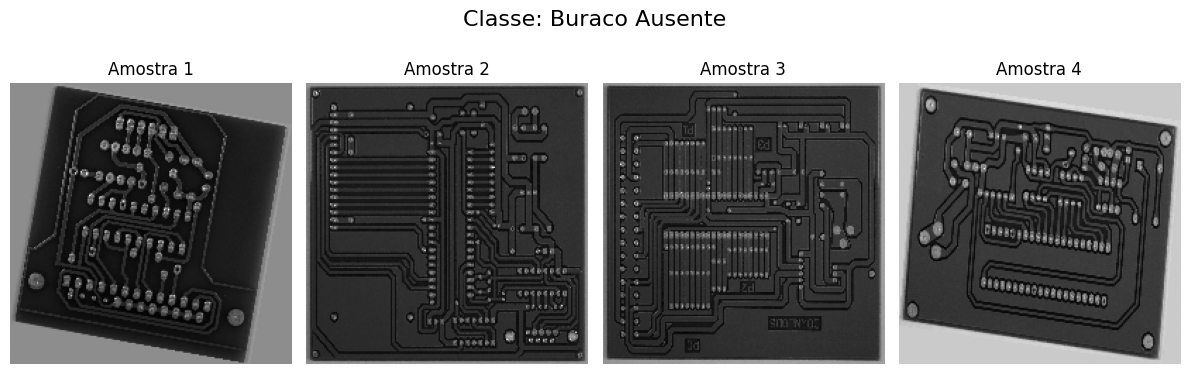

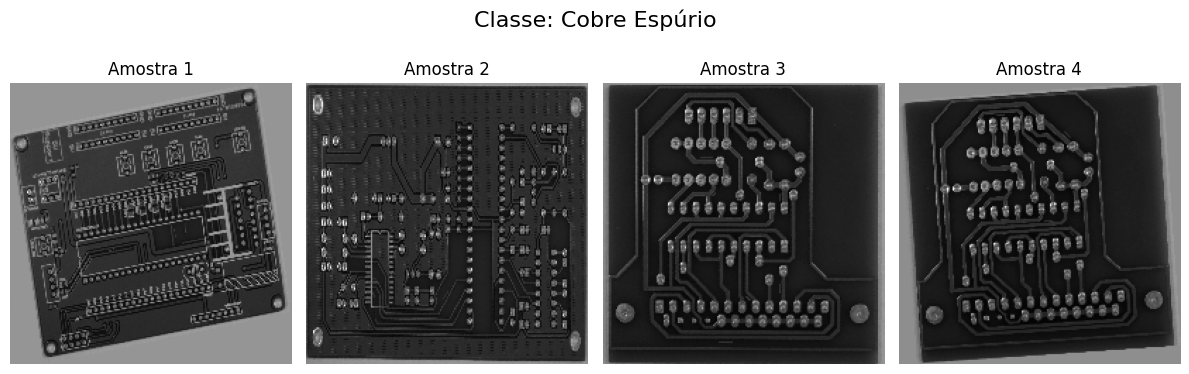

In [ ]:
def show_image_sample(df_data, num_images_per_class=5):
    unique_classes_original = df_data['classe'].unique()

    original_to_translated = {cls_orig: idx_to_class[class_to_idx[cls_orig]] for cls_orig in class_to_idx.keys()}

    for classe_original in unique_classes_original:
        classe_translated = original_to_translated.get(classe_original.lower(), classe_original)

        # Seleciona caminhos de imagens aleatórios para a classe atual
        # Garante que não seleciona mais imagens do que as disponíveis
        class_images = df_data[df_data['classe'] == classe_original]['caminho']
        sample_paths = class_images.sample(min(num_images_per_class, len(class_images)), random_state=42).tolist()

        # Cria uma nova figura para cada classe
        plt.figure(figsize=(num_images_per_class * 3, 4)) # Ajusta o tamanho da figura dinamicamente
        plt.suptitle(f'Classe: {classe_translated}', fontsize=16)

        for i, sample_path in enumerate(sample_paths):
            # Carrega a imagem em tons de cinza
            img = cv2.imread(sample_path, cv2.IMREAD_GRAYSCALE)

            # Redimensiona para uma visualização consistente
            if img is not None:
                img_resized = cv2.resize(img, (200, 200))

                plt.subplot(1, num_images_per_class, i + 1) # 1 linha, num_images_per_class colunas
                plt.imshow(img_resized, cmap='gray')
                plt.title(f'Amostra {i+1}')
                plt.axis('off')
            else:
                print(f"Não foi possível carregar a imagem para a classe {classe_original} em {sample_path}")

        plt.tight_layout(rect=[0, 0.03, 1, 0.95]) # Ajusta o layout para evitar sobreposição do suptitle
        plt.show()

# Chamando a função para exibir as imagens
try:
    show_image_sample(df, num_images_per_class=4)
except NameError:
    print("Erro: A variável 'df' não foi definida. Por favor, certifique-se de executar a célula que carrega e processa os dados para criar o DataFrame 'df' antes de executar esta célula.")

##Visualização de Recortes de Defeitos Processados

Nesta seção, são visualizadas amostras dos recortes de defeitos após o pré-processamento, incluindo a extração das regiões de interesse e redimensionamento, mostrando o que o modelo realmente 'vê'.

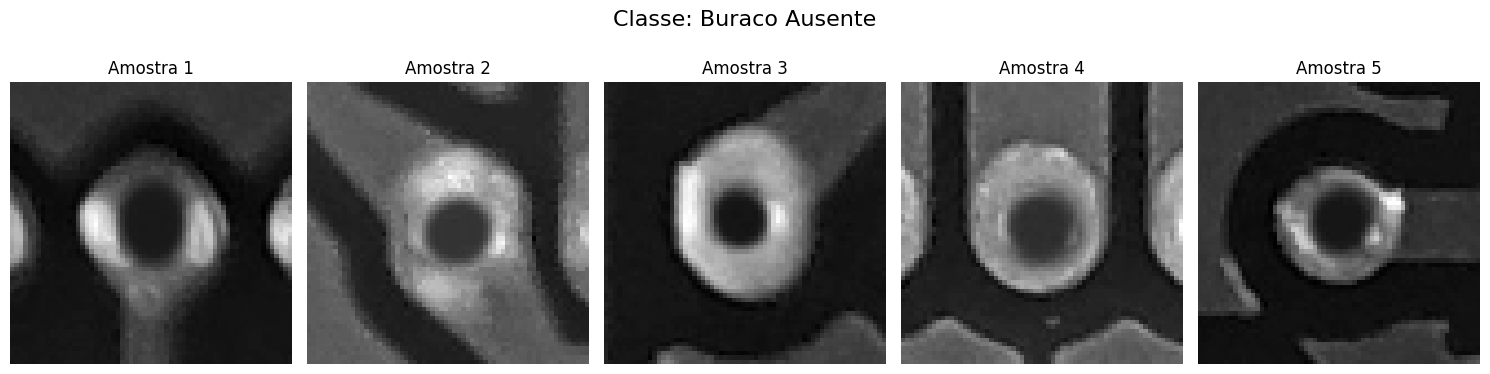

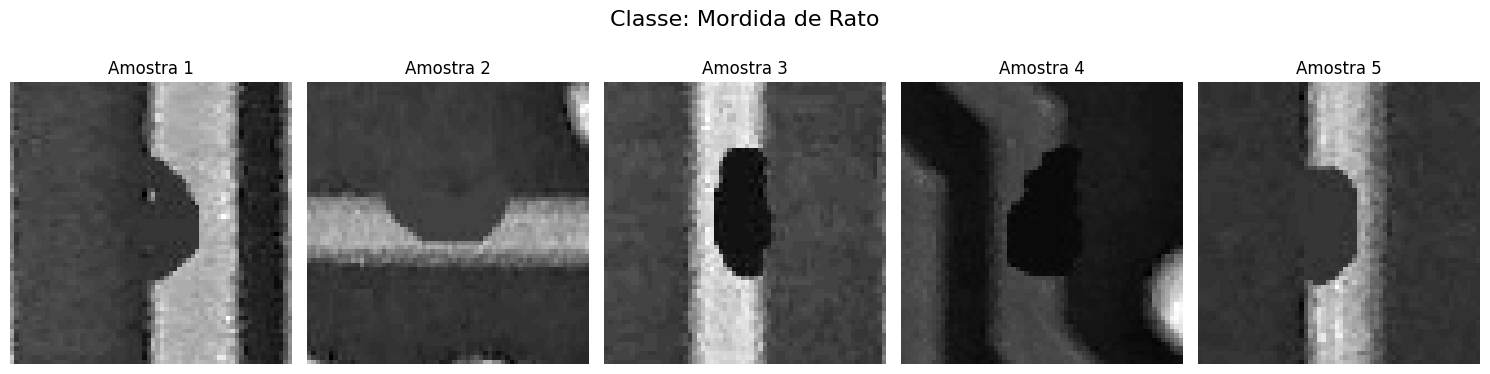

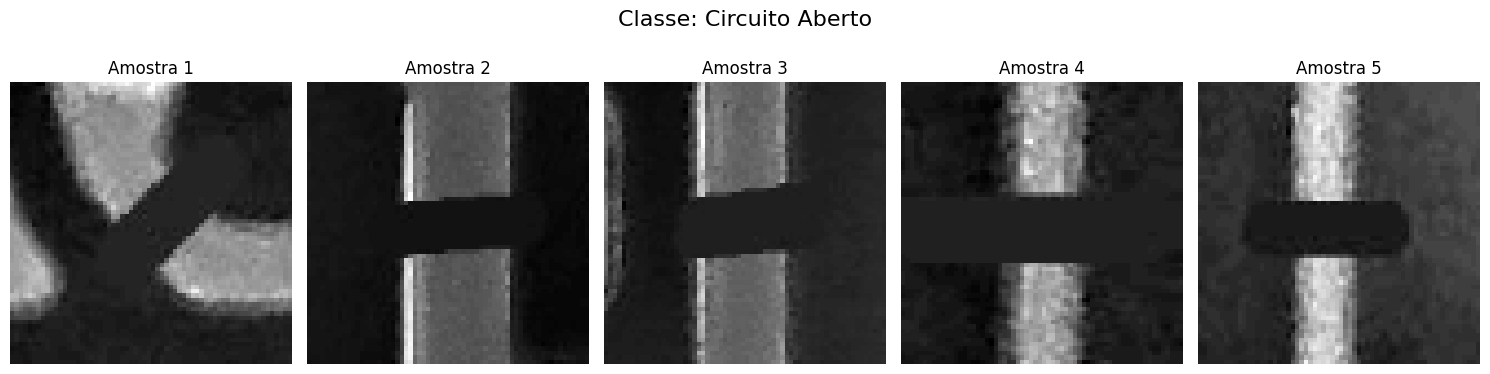

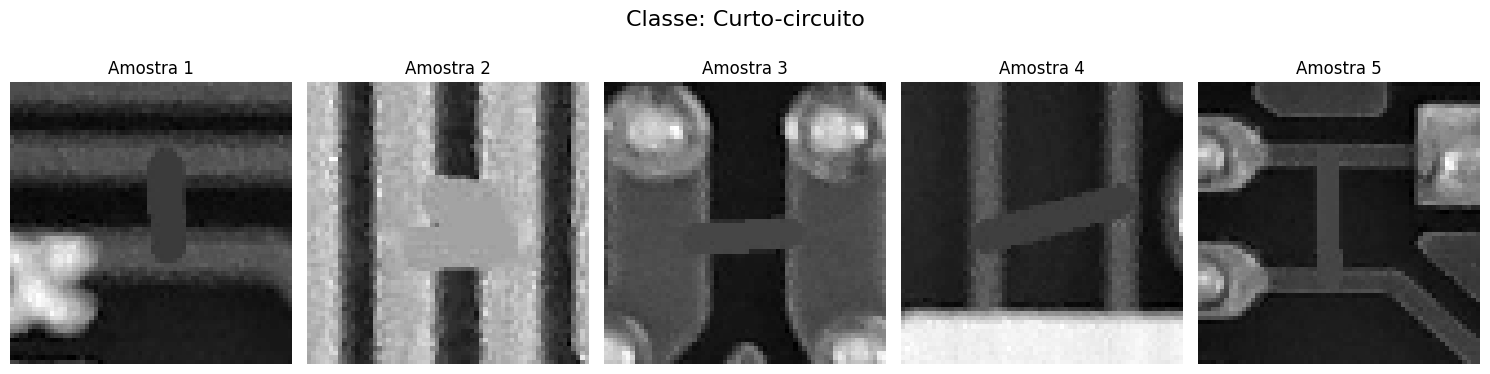

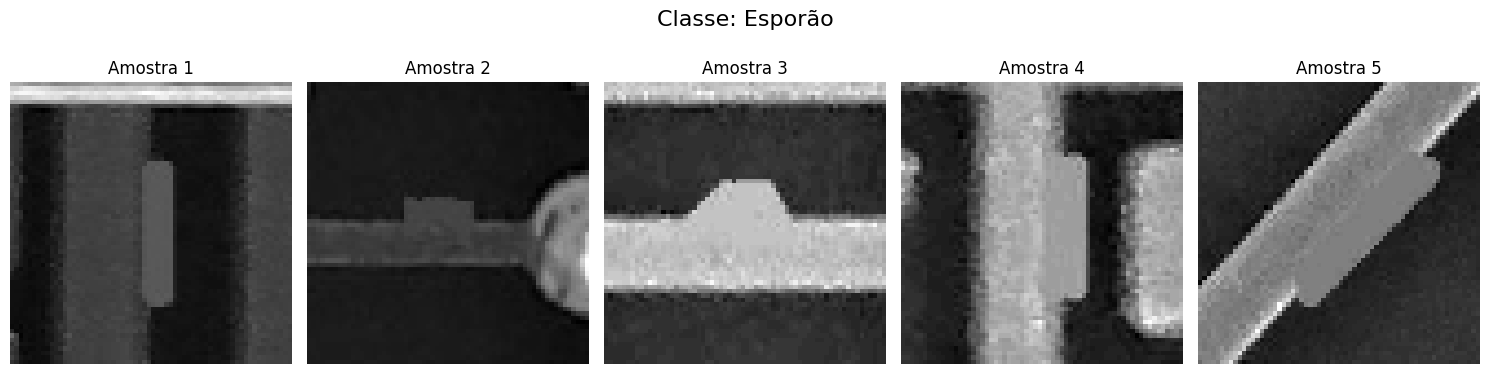

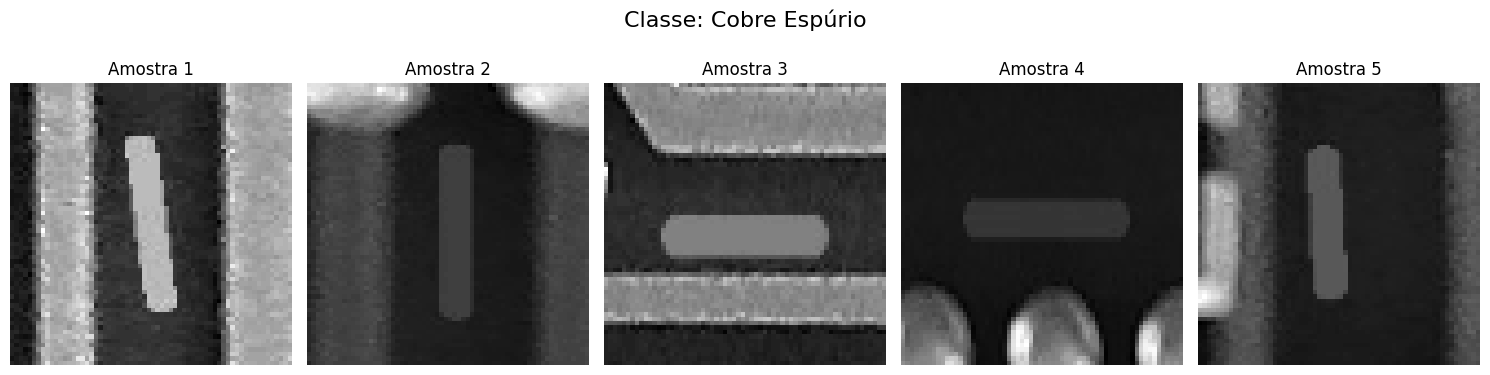

In [ ]:
import matplotlib.pyplot as plt

def mostrar_recortes_por_classe(df, margem=MARGEM, dimensao=DIMENSAO_RECORTE, num_por_classe=5):
    classes_unicas_original = sorted(df['classe'].unique())

    original_to_translated = {cls_orig: idx_to_class[class_to_idx[cls_orig]] for cls_orig in class_to_idx.keys()}

    for classe_original in classes_unicas_original:
        classe_translated = original_to_translated.get(classe_original.lower(), classe_original)

        df_classe = df[df['classe'] == classe_original]
        amostra = df_classe.sample(min(num_por_classe, len(df_classe)), random_state=42)

        plt.figure(figsize=(num_por_classe * 3, 4))
        plt.suptitle(f'Classe: {classe_translated}', fontsize=16)

        for i, (_, linha) in enumerate(amostra.iterrows()):
            img = cv2.imread(linha['caminho_imagem'], cv2.IMREAD_GRAYSCALE)
            h, w = img.shape
            x1 = max(0, linha['xmin'] - margem)
            y1 = max(0, linha['ymin'] - margem)
            x2 = min(w, linha['xmax'] + margem)
            y2 = min(h, linha['ymax'] + margem)
            recorte = img[y1:y2, x1:x2]
            recorte_resized = cv2.resize(recorte, dimensao)

            plt.subplot(1, num_por_classe, i + 1)
            plt.imshow(recorte_resized, cmap='gray')
            plt.title(f'Amostra {i+1}')
            plt.axis('off')

        plt.tight_layout(rect=[0, 0.03, 1, 0.95])
        plt.show()

# Chamada — usa df_recortes (todas as classes, treino+val+teste juntos, só pra inspeção visual)
mostrar_recortes_por_classe(df_recortes, num_por_classe=5)

## Treinamento e comparação dos seis modelos

A partir daqui, cada algoritmo tem duas células principais: uma para executar **GridSearchCV e Optuna** e outra para avaliar as duas melhores versões no conjunto de teste. A validação cruzada é agrupada por `imagem_origem` e os mesmos folds são usados pelos dois métodos. O conjunto de teste só é utilizado na avaliação final.

**Modelos:** CNN, MLP com `KerasClassifier`/SciKeras, Random Forest, Árvore de Decisão, SVM e Gaussian Naive Bayes. Para os modelos clássicos, os atributos de entrada são os vetores HOG já extraídos. Para MLP e SVM, o escalonamento está dentro do `Pipeline` para evitar vazamento entre folds.

In [ ]:
# ============================================================
# CONFIGURAÇÃO COMPARTILHADA — GridSearchCV + Optuna
# ============================================================
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import optuna
import tensorflow as tf
import gc
from IPython.display import display

from sklearn.base import clone
from sklearn.model_selection import GridSearchCV, StratifiedGroupKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix
)
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB
from scikeras.wrappers import KerasClassifier
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Dense, Dropout, Flatten, Conv2D, MaxPooling2D, AveragePooling2D
from tensorflow.keras.optimizers import Adam

warnings.filterwarnings("ignore", category=UserWarning)
optuna.logging.set_verbosity(optuna.logging.WARNING)

SEED = 42
N_SPLITS = 3
N_TRIALS = 5  # Ajuste este valor para controlar o custo computacional
SCORING = "accuracy"  # Métrica principal otimizada pelas duas ferramentas.
TOL_ACURACIA_CV = 0.005   # Diferenças até 0,5 ponto percentual: critério de desempate.
TOL_F1_CV = 0.005
PLOTAR_CURVAS_NN = True  # Desative se quiser evitar o ajuste adicional de diagnóstico.

# Permite que o TensorFlow aloque memória da GPU conforme necessário
gpus = tf.config.list_physical_devices('GPU')

for gpu in gpus:
    try:
        tf.config.experimental.set_memory_growth(gpu, True)
    except RuntimeError as e:
        print(e)

print("GPUs disponíveis:", gpus)

# Os grupos precisam estar alinhados linha a linha com y_treino_idx.
# A validação agrupada impede que recortes da mesma imagem de origem
# apareçam simultaneamente no treino e na validação de um fold.
grupos_treino = df_recortes.iloc[idx_treino]["imagem_origem"].astype(str).to_numpy()
y_treino_idx = np.asarray(y_treino_idx).astype(int)
y_teste_idx = np.asarray(y_teste_idx).astype(int)

if len(grupos_treino) != len(y_treino_idx):
    raise ValueError(
        "O número de grupos não coincide com y_treino_idx. "
        "Verifique se idx_treino indexa as mesmas linhas de df_recortes."
    )

cv_group = StratifiedGroupKFold(n_splits=N_SPLITS, shuffle=True, random_state=SEED)
cv_splits = list(cv_group.split(np.zeros(len(y_treino_idx)), y_treino_idx, groups=grupos_treino))

# Nomes de classes em ordem numérica, respeitando os dicionários já definidos no notebook.
if "idx_to_class" in globals():
    nomes_classes = [idx_to_class[i] for i in range(num_classes)]
elif "class_to_idx" in globals():
    nomes_classes = [nome for nome, indice in sorted(class_to_idx.items(), key=lambda item: item[1])]
else:
    nomes_classes = [str(i) for i in range(num_classes)]

def executar_buscas(nome, estimador, grade_parametros, sugerir_parametros, X, y, n_trials=N_TRIALS):
    """Compara as buscas nos MESMOS folds agrupados; não usa dados de teste."""
    print(f"\n{'=' * 72}\n{nome}: GridSearchCV\n{'=' * 72}")
    inicio_gs = time.time()
    busca_gs = GridSearchCV(
        estimator=estimador,
        param_grid=grade_parametros,
        scoring={"accuracy": "accuracy", "f1_macro": "f1_macro"},
        refit="accuracy",
        cv=cv_splits,
        n_jobs=1,
        verbose=1,
        error_score="raise"
    )
    busca_gs.fit(X, y)
    tempo_gs = time.time() - inicio_gs  # Inclui ajuste final com todos os dados de treino.
    melhor_idx = busca_gs.best_index_

    print(f"Melhor acurácia média CV (GS): {busca_gs.best_score_:.4f}")
    print("Melhores parâmetros GS:", busca_gs.best_params_)
    print(f"Tempo GS (incluindo refit): {tempo_gs / 60:.2f} min")

    print(f"\n{'=' * 72}\n{nome}: Optuna ({n_trials} trials)\n{'=' * 72}")
    def objetivo(trial):
        parametros = sugerir_parametros(trial)
        trial.set_user_attr("parametros_completos", dict(parametros))
        accuracies, f1_scores = [], []
        for idx_fit, idx_valid in cv_splits:
            # Usa a mesma semente do estimador base adotada pelo GridSearchCV.
            modelo = clone(estimador).set_params(**parametros)
            modelo.fit(X[idx_fit], y[idx_fit])
            pred = modelo.predict(X[idx_valid])
            accuracies.append(accuracy_score(y[idx_valid], pred))
            f1_scores.append(f1_score(y[idx_valid], pred, average="macro", zero_division=0))
        trial.set_user_attr("cv_f1_macro", float(np.mean(f1_scores)))
        trial.set_user_attr("cv_acc_std", float(np.std(accuracies)))
        return float(np.mean(accuracies))

    inicio_optuna = time.time()
    estudo = optuna.create_study(
        direction="maximize", sampler=optuna.samplers.TPESampler(seed=SEED)
    )
    estudo.optimize(objetivo, n_trials=n_trials, show_progress_bar=False)

    parametros_optuna_completos = estudo.best_trial.user_attrs["parametros_completos"]
    melhor_optuna = clone(estimador).set_params(**parametros_optuna_completos)
    try:
        melhor_optuna.set_params(random_state=SEED)
    except (ValueError, TypeError):
        pass
    melhor_optuna.fit(X, y)
    tempo_optuna = time.time() - inicio_optuna  # Inclui também o refit do Optuna.

    print(f"Melhor acurácia média CV (Optuna): {estudo.best_value:.4f}")
    print("Melhores parâmetros Optuna:", parametros_optuna_completos)
    print(f"Tempo Optuna (incluindo refit): {tempo_optuna / 60:.2f} min")

    return {
        "grid_search": busca_gs,
        "modelo_gs": busca_gs.best_estimator_,
        "score_cv_gs": float(busca_gs.best_score_),
        "f1_cv_gs": float(busca_gs.cv_results_["mean_test_f1_macro"][melhor_idx]),
        "std_cv_gs": float(busca_gs.cv_results_["std_test_accuracy"][melhor_idx]),
        "parametros_gs": busca_gs.best_params_,
        "tempo_gs_seg": tempo_gs,
        "avaliacoes_gs": len(busca_gs.cv_results_["params"]),
        "estudo_optuna": estudo,
        "modelo_optuna": melhor_optuna,
        "score_cv_optuna": float(estudo.best_value),
        "f1_cv_optuna": float(estudo.best_trial.user_attrs["cv_f1_macro"]),
        "std_cv_optuna": float(estudo.best_trial.user_attrs["cv_acc_std"]),
        "parametros_optuna": parametros_optuna_completos,
        "tempo_optuna_seg": tempo_optuna,
        "avaliacoes_optuna": len(estudo.trials)
    }

resultados_busca = {}
resultados_teste = []
relatorios_teste = {}

def avaliar_modelo(nome, metodo, modelo, X_teste, y_teste, usar_probabilidades=False):
    """Avalia uma única versão final no conjunto de teste, nunca usado na busca."""
    if usar_probabilidades:
        probabilidades = modelo.predict_proba(X_teste)
        pred = np.argmax(probabilidades, axis=1)
    else:
        pred = np.asarray(modelo.predict(X_teste)).reshape(-1).astype(int)

    acc = accuracy_score(y_teste, pred)
    prec_macro = precision_score(y_teste, pred, average="macro", zero_division=0)
    rec_macro = recall_score(y_teste, pred, average="macro", zero_division=0)
    f1_macro = f1_score(y_teste, pred, average="macro", zero_division=0)
    f1_weighted = f1_score(y_teste, pred, average="weighted", zero_division=0)

    print(f"\\n{nome} — {metodo}")
    print(f"Acurácia: {acc:.4f} | Precisão macro: {prec_macro:.4f} | Recall macro: {rec_macro:.4f} | F1 macro: {f1_macro:.4f} | F1 ponderado: {f1_weighted:.4f}")
    relatorio = classification_report(
        y_teste, pred, labels=np.arange(num_classes),
        target_names=[str(c) for c in nomes_classes],
        zero_division=0
    )
    print("\\nRelatório de classificação:")
    print(relatorio)

    cm = confusion_matrix(y_teste, pred, labels=np.arange(num_classes))
    plt.figure(figsize=(8, 6))
    sns.heatmap(
        cm, annot=True, fmt="d", cmap="Blues",
        xticklabels=nomes_classes, yticklabels=nomes_classes
    )
    plt.title(f"Matriz de confusão — {nome} ({metodo})")
    plt.xlabel("Classe predita")
    plt.ylabel("Classe real")
    plt.xticks(rotation=45, ha="right")
    plt.yticks(rotation=0)
    plt.tight_layout()
    plt.show()

    chave = f"{nome}_{metodo}"
    relatorios_teste[chave] = relatorio
    resultados_teste.append({
        "Modelo": nome,
        "Busca": metodo,
        "Acurácia teste": acc,
        "Precisão macro": prec_macro,
        "Recall macro": rec_macro,
        "F1 macro": f1_macro,
        "F1 ponderado": f1_weighted
    })
    return pred

# ------------------------------------------------------------
# Escolha do otimizador: exclusivamente pelas métricas de CV.
# Acurácia é o objetivo principal; F1 macro e tempo desempatem.
# ------------------------------------------------------------
metodos_escolhidos = {}
modelos_escolhidos = {}
comparacoes_buscas = []

def comparar_e_escolher(chave):
    res = resultados_busca[chave]
    metodos = ("GridSearchCV", "Optuna")
    tabela = pd.DataFrame([
        {
            "Modelo": chave, "Método": "GridSearchCV",
            "Acurácia CV": res["score_cv_gs"],
            "DP acurácia CV": res["std_cv_gs"],
            "F1 macro CV": res["f1_cv_gs"],
            "Tempo (min)": res["tempo_gs_seg"] / 60,
            "Configurações": res["avaliacoes_gs"],
            "Treinos CV": res["avaliacoes_gs"] * N_SPLITS,
            "Melhores hiperparâmetros": str(res["parametros_gs"])
        },
        {
            "Modelo": chave, "Método": "Optuna",
            "Acurácia CV": res["score_cv_optuna"],
            "DP acurácia CV": res["std_cv_optuna"],
            "F1 macro CV": res["f1_cv_optuna"],
            "Tempo (min)": res["tempo_optuna_seg"] / 60,
            "Configurações": res["avaliacoes_optuna"],
            "Treinos CV": res["avaliacoes_optuna"] * N_SPLITS,
            "Melhores hiperparâmetros": str(res["parametros_optuna"])
        }
    ])
    diferenca_acc = res["score_cv_gs"] - res["score_cv_optuna"]
    diferenca_f1 = res["f1_cv_gs"] - res["f1_cv_optuna"]
    if abs(diferenca_acc) > TOL_ACURACIA_CV:
        escolhido = "GridSearchCV" if diferenca_acc > 0 else "Optuna"
        justificativa = f"Maior acurácia CV (diferença de {abs(diferenca_acc)*100:.2f} p.p.)."
    elif abs(diferenca_f1) > TOL_F1_CV:
        escolhido = "GridSearchCV" if diferenca_f1 > 0 else "Optuna"
        justificativa = ("Acurácias próximas (até 0,5 p.p.); "
                         f"maior F1 macro CV (diferença de {abs(diferenca_f1)*100:.2f} p.p.).")
    else:
        escolhido = "GridSearchCV" if res["tempo_gs_seg"] <= res["tempo_optuna_seg"] else "Optuna"
        justificativa = ("Acurácia e F1 macro CV próximas (até 0,5 p.p.); "
                         "menor tempo total de busca e reajuste final.")

    metodos_escolhidos[chave] = escolhido
    modelos_escolhidos[chave] = (res["modelo_gs"] if escolhido == "GridSearchCV"
                                else res["modelo_optuna"])
    comparacoes_buscas.extend(tabela.to_dict("records"))

    print(f"\n{'=' * 65}\n{chave}: comparação das ferramentas (validação cruzada)\n{'=' * 65}")
    display(tabela.style.format({
        "Acurácia CV": "{:.4f}", "DP acurácia CV": "{:.4f}",
        "F1 macro CV": "{:.4f}", "Tempo (min)": "{:.2f}"
    }))
    print(f"ESCOLHIDO: {escolhido}. Justificativa: {justificativa}")
    print("Nota: quantidades e espaços de busca podem ser diferentes; "
          "o resultado demonstra o melhor método NESTE experimento, "
          "não uma superioridade universal da ferramenta.")
    return modelos_escolhidos[chave], escolhido


def avaliar_selecionado(chave, titulo, X_teste, usar_probabilidades=False):
    modelo, metodo = comparar_e_escolher(chave)
    return avaliar_modelo(
        titulo, metodo, modelo, X_teste, y_teste_idx,
        usar_probabilidades=usar_probabilidades
    )


def plotar_curvas_keras_escolhido(chave):
    """Somente CNN/MLP selecionadas: um ajuste diagnóstico em um fold agrupado."""
    if not PLOTAR_CURVAS_NN:
        return
    if chave not in {"CNN", "MLP"}:
        raise ValueError("As curvas por época se aplicam à CNN e à MLP.")
    metodo = metodos_escolhidos[chave]
    res = resultados_busca[chave]
    params = res["parametros_gs"] if metodo == "GridSearchCV" else res["parametros_optuna"]
    idx_fit, idx_valid = cv_splits[0]
    assert set(grupos_treino[idx_fit]).isdisjoint(set(grupos_treino[idx_valid]))
    tf.keras.utils.set_random_seed(SEED)

    if chave == "CNN":
        x_fit, x_valid = X_treino_cnn[idx_fit], X_treino_cnn[idx_valid]
        modelo = create_model(
            conv_padding=params.get("model__conv_padding", "same"),
            conv_stride=params.get("model__conv_stride", 1),
            conv_dilation=params.get("model__conv_dilation", 1),
            pool_type=params.get("model__pool_type", "max"),
            learning_rate=params.get("model__learning_rate", 0.001)
        )
        epocas, batch = params.get("epochs", 10), params.get("batch_size", 32)
    else:
        scaler = StandardScaler()
        x_fit = scaler.fit_transform(X_treino_hog_raw[idx_fit]).astype("float32")
        x_valid = scaler.transform(X_treino_hog_raw[idx_valid]).astype("float32")
        modelo = build_mlp_model(
            meta={"n_features_in_": x_fit.shape[1]},
            hidden_units=params.get("mlp__model__hidden_units", 128),
            n_hidden_layers=params.get("mlp__model__n_hidden_layers", 2),
            activation=params.get("mlp__model__activation", "relu"),
            dropout_rate=params.get("mlp__model__dropout_rate", 0.2),
            learning_rate=params.get("mlp__model__learning_rate", 0.001)
        )
        epocas, batch = params.get("mlp__epochs", 20), params.get("mlp__batch_size", 32)

    historico = modelo.fit(
        x_fit, y_treino_idx[idx_fit],
        validation_data=(x_valid, y_treino_idx[idx_valid]),
        epochs=int(epocas), batch_size=int(batch), verbose=0
    ).history
    fig, eixos = plt.subplots(1, 2, figsize=(12, 4))
    ep = range(1, len(historico["loss"]) + 1)
    for eixo, metrica, titulo in zip(
        eixos, ("accuracy", "loss"), ("Acurácia", "Perda (cross-entropy)")
    ):
        eixo.plot(ep, historico[metrica], label="Treinamento")
        eixo.plot(ep, historico["val_" + metrica], label="Validação")
        eixo.set(title=titulo, xlabel="Época", ylabel=titulo)
        eixo.grid(alpha=0.2)
        eixo.legend()
    fig.suptitle(f"{chave} — {metodo}: curvas do melhor hiperparâmetro (fold agrupado)")
    plt.tight_layout()
    plt.show()
    print("Curvas de um novo ajuste de diagnóstico no primeiro fold agrupado: "
          "não são o histórico do modelo final ajustado em todos os dados de treino.")
    del modelo
    gc.collect()

GPUs disponíveis: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [ ]:

# ============================================================
# 1A. CNN — GridSearchCV + Optuna
# Arquitetura original: Conv2D, pooling, Flatten,
# Dropout, Dense e softmax com 6 classes.
# ============================================================

num_classes = 6

# 1. Construção da CNN
def create_model(
    conv_padding="same",
    conv_stride=1,
    conv_dilation=1,
    pool_type="max",
    learning_rate=0.001
):
    model = Sequential()

    model.add(Input(shape=X_treino_cnn.shape[1:]))

    # Primeira camada convolucional
    model.add(Conv2D(
        32,
        kernel_size=(3, 3),
        activation="relu",
        padding=conv_padding,
        strides=(conv_stride, conv_stride),
        dilation_rate=(conv_dilation, conv_dilation)
    ))

    if pool_type == "max":
        model.add(MaxPooling2D(pool_size=(2, 2)))
    elif pool_type == "avg":
        model.add(AveragePooling2D(pool_size=(2, 2)))

    # Segunda camada convolucional
    model.add(Conv2D(
        64,
        kernel_size=(3, 3),
        activation="relu",
        padding=conv_padding,
        strides=(1, 1),
        dilation_rate=(conv_dilation, conv_dilation)
    ))

    if pool_type == "max":
        model.add(MaxPooling2D(pool_size=(2, 2)))
    elif pool_type == "avg":
        model.add(AveragePooling2D(pool_size=(2, 2)))

    # Camadas densas
    model.add(Flatten())
    model.add(Dropout(0.5))
    model.add(Dense(128, activation="relu"))
    model.add(Dropout(0.5))
    model.add(Dense(num_classes, activation="softmax"))

    # Compilação
    model.compile(
        loss="sparse_categorical_crossentropy",
        optimizer=Adam(learning_rate=learning_rate),
        metrics=["accuracy"]
    )

    return model


# 2. Estimador SciKeras
cnn = KerasClassifier(
    model=create_model,
    verbose=0,
    random_state=SEED
)


# 3. GridSearchCV — 16 combinações x 3 folds = 48 fits
param_grid_cnn = {
    "batch_size": [16, 32],
    "epochs": [10],
    "model__conv_padding": ["same", "valid"],
    "model__conv_stride": [1],
    "model__conv_dilation": [1],
    "model__pool_type": ["max", "avg"],
    "model__learning_rate": [0.001, 0.0001]
}


# 4. Espaço de busca do Optuna
def sugerir_cnn(trial):
    stride = trial.suggest_categorical(
        "model__conv_stride", [1, 2]
    )

    # TensorFlow não permite stride > 1 e dilation > 1
    # simultaneamente na mesma camada Conv2D.
    if stride == 2:
        dilation = 1
    else:
        dilation = trial.suggest_categorical(
            "model__conv_dilation", [1, 2]
        )

    params = {
        "batch_size": trial.suggest_categorical(
            "batch_size", [16, 32]
        ),
        "epochs": 10,
        "model__conv_padding": trial.suggest_categorical(
            "model__conv_padding", ["same", "valid"]
        ),
        "model__conv_stride": stride,
        "model__conv_dilation": dilation,
        "model__pool_type": trial.suggest_categorical(
            "model__pool_type", ["max", "avg", "none"]
        ),
        "model__learning_rate": trial.suggest_float(
            "model__learning_rate",
            1e-4,
            1e-3,
            log=True
        )
    }

    return params


# 5. Executar GridSearchCV e Optuna
resultados_busca["CNN"] = executar_buscas(
    nome="CNN",
    estimador=cnn,
    grade_parametros=param_grid_cnn,
    sugerir_parametros=sugerir_cnn,
    X=X_treino_cnn,
    y=y_treino_idx,
    n_trials=N_TRIALS
)


# 6. Armazenar os melhores modelos
best_model_gs_cnn = resultados_busca["CNN"]["modelo_gs"]
best_model_optuna_cnn = resultados_busca["CNN"]["modelo_optuna"]



CNN: GridSearchCV
Fitting 3 folds for each of 16 candidates, totalling 48 fits


/usr/local/lib/python3.13/dist-packages/numpy/ma/core.py:2881: RuntimeWarning: invalid value encountered in cast
  _data = np.array(data, dtype=dtype, copy=copy,


Melhor acurácia média CV (GS): 0.9166
Melhores parâmetros GS: {'batch_size': 16, 'epochs': 10, 'model__conv_dilation': 1, 'model__conv_padding': 'valid', 'model__conv_stride': 1, 'model__learning_rate': 0.001, 'model__pool_type': 'avg'}
Tempo GS (incluindo refit): 7.03 min

CNN: Optuna (5 trials)
Melhor acurácia média CV (Optuna): 0.9005
Melhores parâmetros Optuna: {'batch_size': 32, 'epochs': 10, 'model__conv_padding': 'valid', 'model__conv_stride': 2, 'model__conv_dilation': 1, 'model__pool_type': 'none', 'model__learning_rate': 0.0005958443469672521}
Tempo Optuna (incluindo refit): 2.66 min



CNN: comparação das ferramentas (validação cruzada)


,Modelo,Método,Acurácia CV,DP acurácia CV,F1 macro CV,Tempo (min),Configurações,Treinos CV,Melhores hiperparâmetros
0,CNN,GridSearchCV,0.9166,0.0065,0.9169,7.03,16,48,"{'batch_size': 16, 'epochs': 10, 'model__conv_dilation': 1, 'model__conv_padding': 'valid', 'model__conv_stride': 1, 'model__learning_rate': 0.001, 'model__pool_type': 'avg'}"
1,CNN,Optuna,0.9005,0.0092,0.9006,2.66,5,15,"{'batch_size': 32, 'epochs': 10, 'model__conv_padding': 'valid', 'model__conv_stride': 2, 'model__conv_dilation': 1, 'model__pool_type': 'none', 'model__learning_rate': 0.0005958443469672521}"


ESCOLHIDO: GridSearchCV. Justificativa: Maior acurácia CV (diferença de 1.61 p.p.).
Nota: quantidades e espaços de busca podem ser diferentes; o resultado demonstra o melhor método NESTE experimento, não uma superioridade universal da ferramenta.
\nCNN — GridSearchCV
Acurácia: 0.9373 | Precisão macro: 0.9350 | Recall macro: 0.9330 | F1 macro: 0.9336 | F1 ponderado: 0.9374
\nRelatório de classificação:
                 precision    recall  f1-score   support

 Buraco Ausente       0.99      0.96      0.98       112
Mordida de Rato       0.94      0.89      0.92        73
Circuito Aberto       0.93      0.96      0.95       102
 Curto-circuito       0.92      0.89      0.91        95
        Esporão       0.94      0.96      0.95       125
  Cobre Espúrio       0.88      0.93      0.90        83

       accuracy                           0.94       590
      macro avg       0.93      0.93      0.93       590
   weighted avg       0.94      0.94      0.94       590



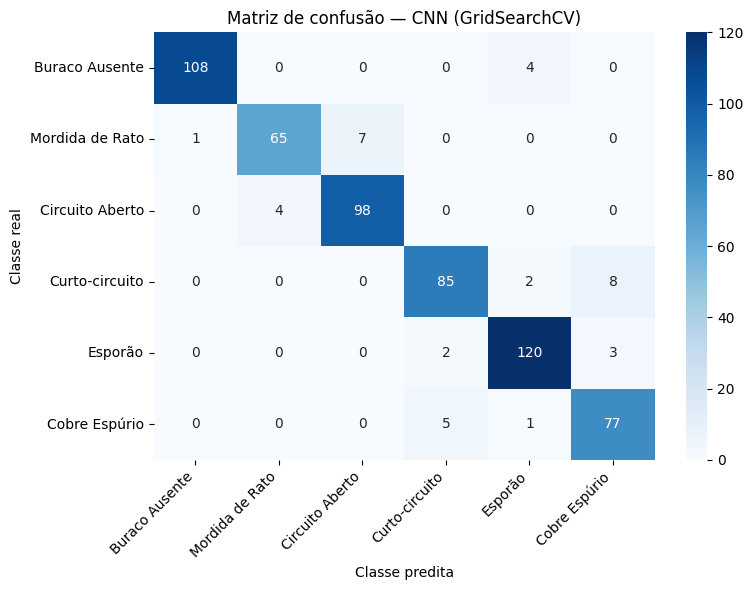

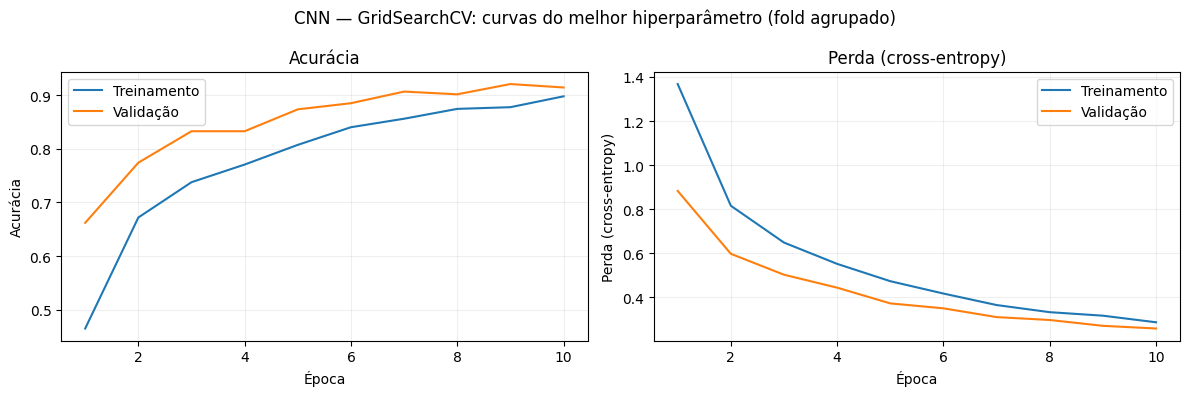

Curvas de um novo ajuste de diagnóstico no primeiro fold agrupado: não são o histórico do modelo final ajustado em todos os dados de treino.


In [ ]:
# ============================================================
# CNN — escolher GS/Optuna via CV; avaliar APENAS o escolhido
# ============================================================
pred_cnn = avaliar_selecionado(
    "CNN", "CNN", X_teste_cnn, usar_probabilidades=True
)
plotar_curvas_keras_escolhido("CNN")

In [ ]:
# ============================================================
# 2A. MLP — KerasClassifier/SciKeras + GridSearchCV + Optuna
# Usa HOG; o StandardScaler fica dentro do Pipeline para ser
# ajustado apenas com os dados de treino de cada fold.
# ============================================================
def build_mlp_model(meta, hidden_units=128, n_hidden_layers=2,
                    activation="relu", dropout_rate=0.2,
                    learning_rate=0.001):
    input_dim = meta["n_features_in_"]
    model = Sequential()
    model.add(Input(shape=(input_dim,)))
    for _ in range(n_hidden_layers):
        model.add(Dense(hidden_units, activation=activation))
        if dropout_rate > 0:
            model.add(Dropout(dropout_rate))
    model.add(Dense(num_classes, activation="softmax"))
    model.compile(
        optimizer=Adam(learning_rate=learning_rate),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )
    return model

mlp_keras = KerasClassifier(
    model=build_mlp_model,
    verbose=1,
    random_state=SEED
)
mlp_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("mlp", mlp_keras)
])

param_grid_mlp = {
    "mlp__model__hidden_units": [64, 128],
    "mlp__model__n_hidden_layers": [1, 2],
    "mlp__model__activation": ["relu", "tanh"],
    "mlp__model__dropout_rate": [0.0, 0.2],
    "mlp__model__learning_rate": [0.001],
    "mlp__batch_size": [16, 32],
    "mlp__epochs": [20]
}

def sugerir_mlp(trial):
    return {
        "mlp__model__hidden_units": trial.suggest_categorical("mlp__model__hidden_units", [64, 128, 256]),
        "mlp__model__n_hidden_layers": trial.suggest_int("mlp__model__n_hidden_layers", 1, 3),
        "mlp__model__activation": trial.suggest_categorical("mlp__model__activation", ["relu", "tanh"]),
        "mlp__model__dropout_rate": trial.suggest_float("mlp__model__dropout_rate", 0.0, 0.4),
        "mlp__model__learning_rate": trial.suggest_float("mlp__model__learning_rate", 1e-4, 1e-2, log=True),
        "mlp__batch_size": trial.suggest_categorical("mlp__batch_size", [16, 32]),
        "mlp__epochs": trial.suggest_categorical("mlp__epochs", [15, 20, 30])
    }

resultados_busca["MLP"] = executar_buscas(
    "MLP", mlp_pipeline, param_grid_mlp, sugerir_mlp,
    X_treino_hog_raw, y_treino_idx, n_trials=N_TRIALS
)
best_model_gs_mlp = resultados_busca["MLP"]["modelo_gs"]
best_model_optuna_mlp = resultados_busca["MLP"]["modelo_optuna"]


MLP: GridSearchCV
Fitting 3 folds for each of 32 candidates, totalling 96 fits
Epoch 1/20
99/99 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.5712 - loss: 1.1021
Epoch 2/20
99/99 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.7986 - loss: 0.5657
Epoch 3/20
99/99 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8651 - loss: 0.4137
Epoch 4/20
99/99 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9088 - loss: 0.3224
Epoch 5/20
99/99 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9341 - loss: 0.2599
Epoch 6/20
99/99 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.9557 - loss: 0.2133
Epoch 7/20
99/99 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - accuracy: 0.9639 - loss: 0.1767
Epoch 8/20
99/99 ━━━━━━━━━━━━━━━━━━━━ 2s 12ms/step - accuracy: 0.9721 - loss: 0.1484
Epoch 9/20
99/99 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/step - accuracy: 0.9778 - loss: 0.1253
Epoch 10/20
99/99 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - accuracy: 0.9816 - loss: 0.1064
Epoch 11/20
99/99 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - accuracy: 0.9867 - lo


MLP: comparação das ferramentas (validação cruzada)


,Modelo,Método,Acurácia CV,DP acurácia CV,F1 macro CV,Tempo (min),Configurações,Treinos CV,Melhores hiperparâmetros
0,MLP,GridSearchCV,0.8527,0.0091,0.8485,18.37,32,96,"{'mlp__batch_size': 32, 'mlp__epochs': 20, 'mlp__model__activation': 'relu', 'mlp__model__dropout_rate': 0.0, 'mlp__model__hidden_units': 128, 'mlp__model__learning_rate': 0.001, 'mlp__model__n_hidden_layers': 2}"
1,MLP,Optuna,0.8523,0.0086,0.8498,4.42,5,15,"{'mlp__model__hidden_units': 256, 'mlp__model__n_hidden_layers': 1, 'mlp__model__activation': 'relu', 'mlp__model__dropout_rate': 0.2650089137415928, 'mlp__model__learning_rate': 0.0004201672054372534, 'mlp__batch_size': 32, 'mlp__epochs': 20}"


ESCOLHIDO: Optuna. Justificativa: Acurácia e F1 macro CV próximas (até 0,5 p.p.); menor tempo total de busca e reajuste final.
Nota: quantidades e espaços de busca podem ser diferentes; o resultado demonstra o melhor método NESTE experimento, não uma superioridade universal da ferramenta.
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step 
\nMLP — Optuna
Acurácia: 0.8678 | Precisão macro: 0.8606 | Recall macro: 0.8667 | F1 macro: 0.8626 | F1 ponderado: 0.8672
\nRelatório de classificação:
                 precision    recall  f1-score   support

 Buraco Ausente       1.00      1.00      1.00       112
Mordida de Rato       0.76      0.79      0.78        73
Circuito Aberto       0.87      0.87      0.87       102
 Curto-circuito       0.84      0.79      0.82        95
        Esporão       0.85      0.79      0.82       125
  Cobre Espúrio       0.83      0.95      0.89        83

       accuracy                           0.87       590
      macro avg       0.86      0.87      0.86       590
   

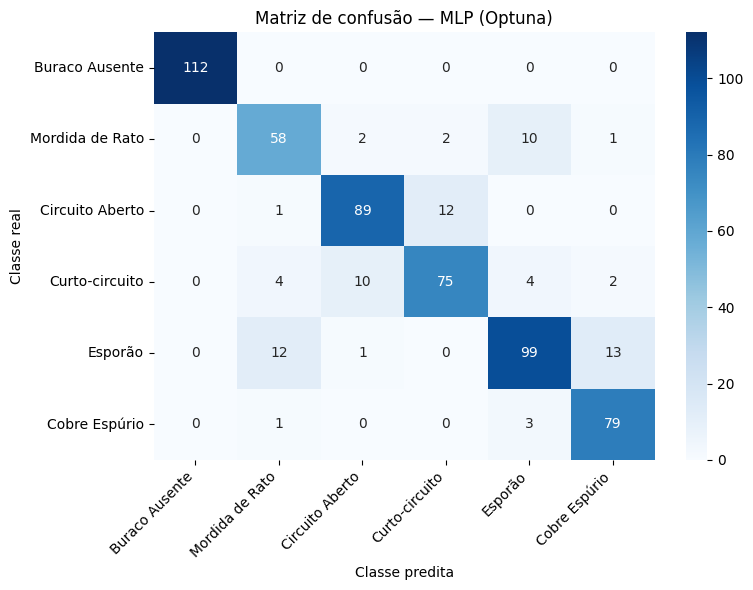

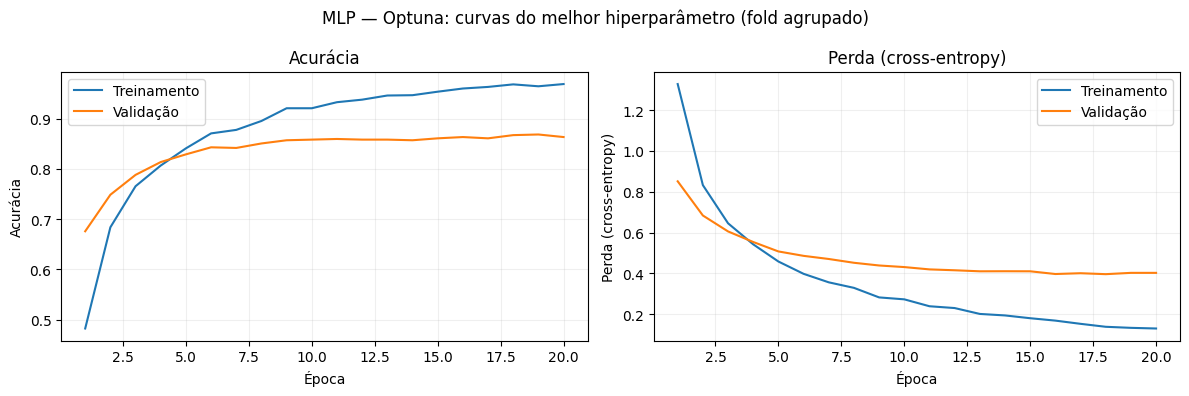

Curvas de um novo ajuste de diagnóstico no primeiro fold agrupado: não são o histórico do modelo final ajustado em todos os dados de treino.


In [ ]:
# ============================================================
# MLP — escolher GS/Optuna via CV; avaliar APENAS o escolhido
# ============================================================
pred_mlp = avaliar_selecionado(
    "MLP", "MLP", X_teste_hog_raw, usar_probabilidades=False
)
plotar_curvas_keras_escolhido("MLP")

In [ ]:
# ============================================================
# 3A. Random Forest (RF) — GridSearchCV + Optuna
# Usa os vetores HOG sem escalonamento, apropriado para árvores.
# ============================================================
rf = RandomForestClassifier(random_state=SEED, n_jobs=1)
param_grid_rf = {
    "n_estimators": [100, 200],
    "max_depth": [None, 20],
    "min_samples_split": [2, 5],
    "min_samples_leaf": [1, 2],
    "max_features": ["sqrt"]
}

def sugerir_rf(trial):
    return {
        "n_estimators": trial.suggest_categorical("n_estimators", [100, 200, 300]),
        "max_depth": trial.suggest_categorical("max_depth", [None, 10, 20, 30]),
        "min_samples_split": trial.suggest_int("min_samples_split", 2, 10),
        "min_samples_leaf": trial.suggest_int("min_samples_leaf", 1, 4),
        "max_features": trial.suggest_categorical("max_features", ["sqrt", "log2", None])
    }

resultados_busca["RF"] = executar_buscas(
    "Random Forest", rf, param_grid_rf, sugerir_rf,
    X_treino_hog_raw, y_treino_idx, n_trials=N_TRIALS
)
best_model_gs_rf = resultados_busca["RF"]["modelo_gs"]
best_model_optuna_rf = resultados_busca["RF"]["modelo_optuna"]


Random Forest: GridSearchCV
Fitting 3 folds for each of 16 candidates, totalling 48 fits
Melhor acurácia média CV (GS): 0.8536
Melhores parâmetros GS: {'max_depth': None, 'max_features': 'sqrt', 'min_samples_leaf': 1, 'min_samples_split': 2, 'n_estimators': 200}
Tempo GS (incluindo refit): 3.00 min

Random Forest: Optuna (5 trials)
Melhor acurácia média CV (Optuna): 0.8603
Melhores parâmetros Optuna: {'n_estimators': 200, 'max_depth': 30, 'min_samples_split': 3, 'min_samples_leaf': 1, 'max_features': 'log2'}
Tempo Optuna (incluindo refit): 10.83 min



RF: comparação das ferramentas (validação cruzada)


,Modelo,Método,Acurácia CV,DP acurácia CV,F1 macro CV,Tempo (min),Configurações,Treinos CV,Melhores hiperparâmetros
0,RF,GridSearchCV,0.8536,0.0028,0.8489,3.00,16,48,"{'max_depth': None, 'max_features': 'sqrt', 'min_samples_leaf': 1, 'min_samples_split': 2, 'n_estimators': 200}"
1,RF,Optuna,0.8603,0.0122,0.8557,10.83,5,15,"{'n_estimators': 200, 'max_depth': 30, 'min_samples_split': 3, 'min_samples_leaf': 1, 'max_features': 'log2'}"


ESCOLHIDO: Optuna. Justificativa: Maior acurácia CV (diferença de 0.67 p.p.).
Nota: quantidades e espaços de busca podem ser diferentes; o resultado demonstra o melhor método NESTE experimento, não uma superioridade universal da ferramenta.
\nRandom Forest — Optuna
Acurácia: 0.8576 | Precisão macro: 0.8550 | Recall macro: 0.8663 | F1 macro: 0.8532 | F1 ponderado: 0.8558
\nRelatório de classificação:
                 precision    recall  f1-score   support

 Buraco Ausente       1.00      1.00      1.00       112
Mordida de Rato       0.67      0.88      0.76        73
Circuito Aberto       0.90      0.95      0.92       102
 Curto-circuito       0.93      0.81      0.87        95
        Esporão       0.87      0.63      0.73       125
  Cobre Espúrio       0.76      0.93      0.84        83

       accuracy                           0.86       590
      macro avg       0.86      0.87      0.85       590
   weighted avg       0.87      0.86      0.86       590



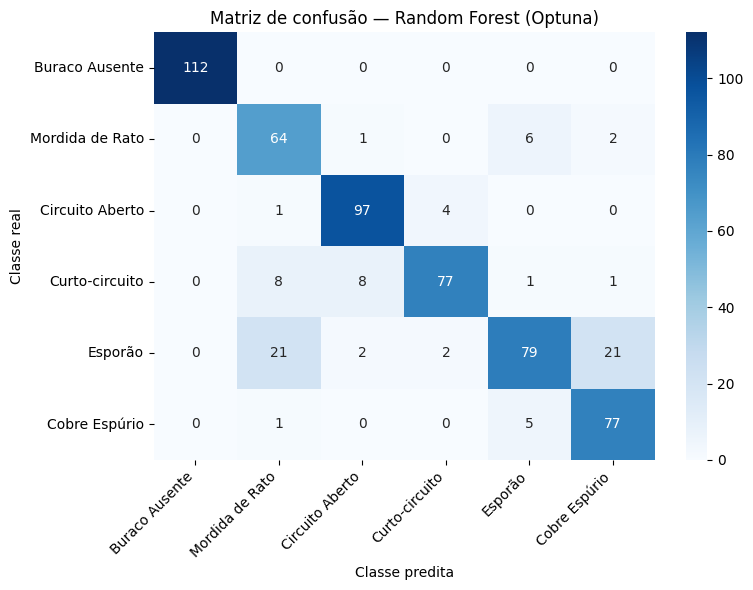

In [ ]:
# ============================================================
# Random Forest — escolher GS/Optuna via CV; avaliar APENAS o escolhido
# ============================================================
pred_rf = avaliar_selecionado(
    "RF", "Random Forest", X_teste_hog_raw, usar_probabilidades=False
)

In [ ]:
# ============================================================
# 4A. Árvore de Decisão (AD) — GridSearchCV + Optuna
# ============================================================
ad = DecisionTreeClassifier(random_state=SEED)
param_grid_ad = {
    "criterion": ["gini", "entropy"],
    "max_depth": [None, 10, 20],
    "min_samples_split": [2, 5],
    "min_samples_leaf": [1, 2],
    "max_features": [None, "sqrt"]
}

def sugerir_ad(trial):
    return {
        "criterion": trial.suggest_categorical("criterion", ["gini", "entropy", "log_loss"]),
        "max_depth": trial.suggest_categorical("max_depth", [None, 5, 10, 20, 30]),
        "min_samples_split": trial.suggest_int("min_samples_split", 2, 12),
        "min_samples_leaf": trial.suggest_int("min_samples_leaf", 1, 6),
        "max_features": trial.suggest_categorical("max_features", [None, "sqrt", "log2"])
    }

resultados_busca["AD"] = executar_buscas(
    "Árvore de Decisão", ad, param_grid_ad, sugerir_ad,
    X_treino_hog_raw, y_treino_idx, n_trials=N_TRIALS
)
best_model_gs_ad = resultados_busca["AD"]["modelo_gs"]
best_model_optuna_ad = resultados_busca["AD"]["modelo_optuna"]


Árvore de Decisão: GridSearchCV
Fitting 3 folds for each of 48 candidates, totalling 144 fits
Melhor acurácia média CV (GS): 0.6399
Melhores parâmetros GS: {'criterion': 'entropy', 'max_depth': None, 'max_features': None, 'min_samples_leaf': 2, 'min_samples_split': 5}
Tempo GS (incluindo refit): 1.01 min

Árvore de Decisão: Optuna (5 trials)
Melhor acurácia média CV (Optuna): 0.6179
Melhores parâmetros Optuna: {'criterion': 'gini', 'max_depth': None, 'min_samples_split': 6, 'min_samples_leaf': 2, 'max_features': None}
Tempo Optuna (incluindo refit): 0.06 min



AD: comparação das ferramentas (validação cruzada)


,Modelo,Método,Acurácia CV,DP acurácia CV,F1 macro CV,Tempo (min),Configurações,Treinos CV,Melhores hiperparâmetros
0,AD,GridSearchCV,0.6399,0.0168,0.6366,1.01,48,144,"{'criterion': 'entropy', 'max_depth': None, 'max_features': None, 'min_samples_leaf': 2, 'min_samples_split': 5}"
1,AD,Optuna,0.6179,0.0250,0.6146,0.06,5,15,"{'criterion': 'gini', 'max_depth': None, 'min_samples_split': 6, 'min_samples_leaf': 2, 'max_features': None}"


ESCOLHIDO: GridSearchCV. Justificativa: Maior acurácia CV (diferença de 2.20 p.p.).
Nota: quantidades e espaços de busca podem ser diferentes; o resultado demonstra o melhor método NESTE experimento, não uma superioridade universal da ferramenta.
\nÁrvore de Decisão — GridSearchCV
Acurácia: 0.6593 | Precisão macro: 0.6621 | Recall macro: 0.6631 | F1 macro: 0.6571 | F1 ponderado: 0.6621
\nRelatório de classificação:
                 precision    recall  f1-score   support

 Buraco Ausente       0.95      0.90      0.93       112
Mordida de Rato       0.43      0.66      0.52        73
Circuito Aberto       0.62      0.64      0.63       102
 Curto-circuito       0.64      0.58      0.61        95
        Esporão       0.61      0.48      0.54       125
  Cobre Espúrio       0.72      0.72      0.72        83

       accuracy                           0.66       590
      macro avg       0.66      0.66      0.66       590
   weighted avg       0.67      0.66      0.66       590



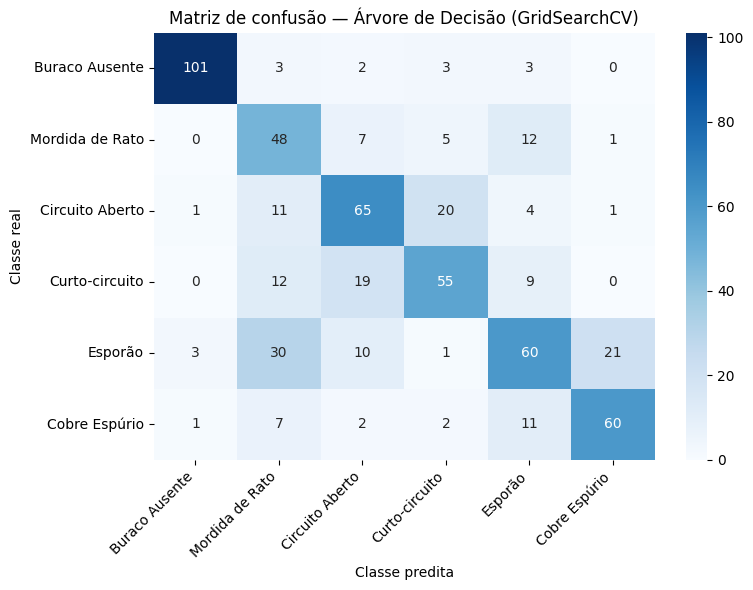

In [ ]:
# ============================================================
# Árvore de Decisão — escolher GS/Optuna via CV; avaliar APENAS o escolhido
# ============================================================
pred_ad = avaliar_selecionado(
    "AD", "Árvore de Decisão", X_teste_hog_raw, usar_probabilidades=False
)

In [ ]:
# ============================================================
# 5A. SVM — GridSearchCV + Optuna
# O escalonamento ocorre dentro do Pipeline, em cada fold.
# ============================================================
svm_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("svm", SVC())
])
param_grid_svm = [
    {"svm__kernel": ["linear"], "svm__C": [0.1, 1, 10]},
    {"svm__kernel": ["rbf"], "svm__C": [0.1, 1, 10], "svm__gamma": ["scale", "auto"]}
]

def sugerir_svm(trial):
    kernel = trial.suggest_categorical("svm__kernel", ["linear", "rbf"])
    params = {
        "svm__kernel": kernel,
        "svm__C": trial.suggest_float("svm__C", 1e-2, 1e2, log=True)
    }
    if kernel == "rbf":
        params["svm__gamma"] = trial.suggest_categorical("svm__gamma", ["scale", "auto"])
    return params

resultados_busca["SVM"] = executar_buscas(
    "SVM", svm_pipeline, param_grid_svm, sugerir_svm,
    X_treino_hog_raw, y_treino_idx, n_trials=N_TRIALS
)
best_model_gs_svm = resultados_busca["SVM"]["modelo_gs"]
best_model_optuna_svm = resultados_busca["SVM"]["modelo_optuna"]


SVM: GridSearchCV
Fitting 3 folds for each of 9 candidates, totalling 27 fits
Melhor acurácia média CV (GS): 0.8713
Melhores parâmetros GS: {'svm__C': 10, 'svm__gamma': 'scale', 'svm__kernel': 'rbf'}
Tempo GS (incluindo refit): 0.27 min

SVM: Optuna (5 trials)
Melhor acurácia média CV (Optuna): 0.8709
Melhores parâmetros Optuna: {'svm__kernel': 'rbf', 'svm__C': 8.471801418819979, 'svm__gamma': 'scale'}
Tempo Optuna (incluindo refit): 0.16 min



SVM: comparação das ferramentas (validação cruzada)


,Modelo,Método,Acurácia CV,DP acurácia CV,F1 macro CV,Tempo (min),Configurações,Treinos CV,Melhores hiperparâmetros
0,SVM,GridSearchCV,0.8713,0.0028,0.8682,0.27,9,27,"{'svm__C': 10, 'svm__gamma': 'scale', 'svm__kernel': 'rbf'}"
1,SVM,Optuna,0.8709,0.0033,0.8678,0.16,5,15,"{'svm__kernel': 'rbf', 'svm__C': 8.471801418819979, 'svm__gamma': 'scale'}"


ESCOLHIDO: Optuna. Justificativa: Acurácia e F1 macro CV próximas (até 0,5 p.p.); menor tempo total de busca e reajuste final.
Nota: quantidades e espaços de busca podem ser diferentes; o resultado demonstra o melhor método NESTE experimento, não uma superioridade universal da ferramenta.
\nSVM — Optuna
Acurácia: 0.8983 | Precisão macro: 0.8923 | Recall macro: 0.8999 | F1 macro: 0.8948 | F1 ponderado: 0.8980
\nRelatório de classificação:
                 precision    recall  f1-score   support

 Buraco Ausente       1.00      1.00      1.00       112
Mordida de Rato       0.76      0.85      0.80        73
Circuito Aberto       0.92      0.95      0.94       102
 Curto-circuito       0.92      0.86      0.89        95
        Esporão       0.88      0.78      0.83       125
  Cobre Espúrio       0.88      0.95      0.91        83

       accuracy                           0.90       590
      macro avg       0.89      0.90      0.89       590
   weighted avg       0.90      0.90      0

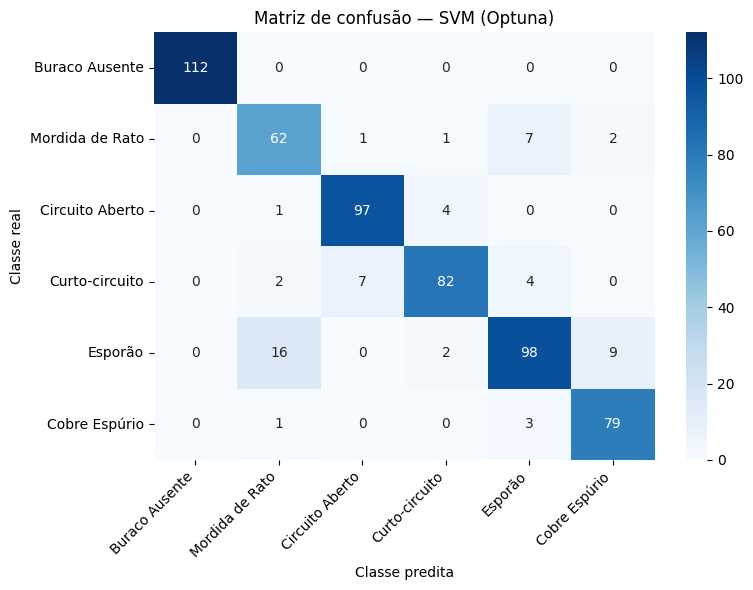

In [ ]:
# ============================================================
# SVM — escolher GS/Optuna via CV; avaliar APENAS o escolhido
# ============================================================
pred_svm = avaliar_selecionado(
    "SVM", "SVM", X_teste_hog_raw, usar_probabilidades=False
)

In [ ]:
# ============================================================
# 6A. Naive Bayes — GaussianNB + GridSearchCV + Optuna
# GaussianNB é a variante escolhida para vetores HOG contínuos.
# ============================================================
nb = GaussianNB()
param_grid_nb = {
    "var_smoothing": [1e-11, 1e-9, 1e-7]
}

def sugerir_nb(trial):
    return {
        "var_smoothing": trial.suggest_float("var_smoothing", 1e-12, 1e-6, log=True)
    }

resultados_busca["NB"] = executar_buscas(
    "Naive Bayes (GaussianNB)", nb, param_grid_nb, sugerir_nb,
    X_treino_hog_raw, y_treino_idx, n_trials=N_TRIALS
)
best_model_gs_nb = resultados_busca["NB"]["modelo_gs"]
best_model_optuna_nb = resultados_busca["NB"]["modelo_optuna"]


Naive Bayes (GaussianNB): GridSearchCV
Fitting 3 folds for each of 3 candidates, totalling 9 fits
Melhor acurácia média CV (GS): 0.6495
Melhores parâmetros GS: {'var_smoothing': 1e-11}
Tempo GS (incluindo refit): 0.00 min

Naive Bayes (GaussianNB): Optuna (5 trials)
Melhor acurácia média CV (Optuna): 0.6495
Melhores parâmetros Optuna: {'var_smoothing': 1.7670169402947963e-10}
Tempo Optuna (incluindo refit): 0.00 min



NB: comparação das ferramentas (validação cruzada)


,Modelo,Método,Acurácia CV,DP acurácia CV,F1 macro CV,Tempo (min),Configurações,Treinos CV,Melhores hiperparâmetros
0,NB,GridSearchCV,0.6495,0.0181,0.6470,0.00,3,9,{'var_smoothing': 1e-11}
1,NB,Optuna,0.6495,0.0181,0.6470,0.00,5,15,{'var_smoothing': 1.7670169402947963e-10}


ESCOLHIDO: GridSearchCV. Justificativa: Acurácia e F1 macro CV próximas (até 0,5 p.p.); menor tempo total de busca e reajuste final.
Nota: quantidades e espaços de busca podem ser diferentes; o resultado demonstra o melhor método NESTE experimento, não uma superioridade universal da ferramenta.
\nNaive Bayes — GridSearchCV
Acurácia: 0.6458 | Precisão macro: 0.6533 | Recall macro: 0.6457 | F1 macro: 0.6409 | F1 ponderado: 0.6510
\nRelatório de classificação:
                 precision    recall  f1-score   support

 Buraco Ausente       1.00      0.96      0.98       112
Mordida de Rato       0.36      0.56      0.44        73
Circuito Aberto       0.80      0.64      0.71       102
 Curto-circuito       0.55      0.65      0.60        95
        Esporão       0.58      0.41      0.48       125
  Cobre Espúrio       0.63      0.65      0.64        83

       accuracy                           0.65       590
      macro avg       0.65      0.65      0.64       590
   weighted avg       0

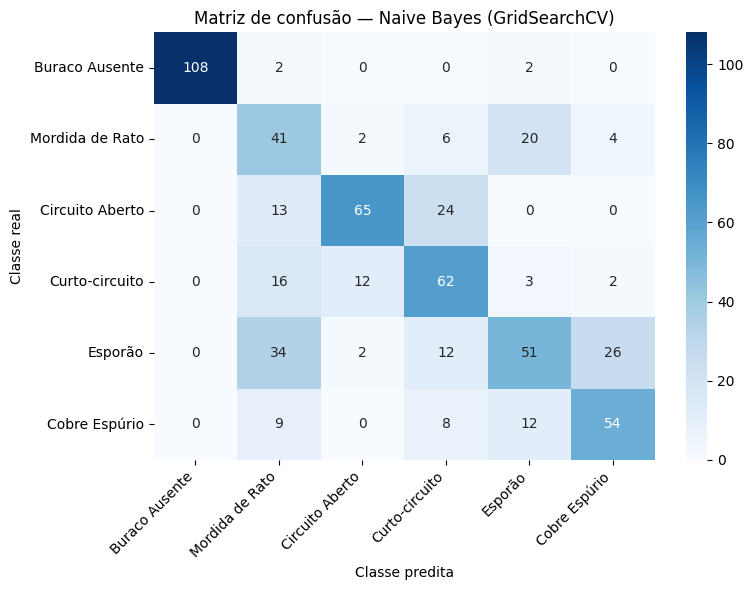

In [ ]:
# ============================================================
# Naive Bayes — escolher GS/Optuna via CV; avaliar APENAS o escolhido
# ============================================================
pred_nb = avaliar_selecionado(
    "NB", "Naive Bayes", X_teste_hog_raw, usar_probabilidades=False
)

## Síntese dos resultados: busca e classificação final

Para cada algoritmo, o método de busca é escolhido **antes de qualquer avaliação no teste**, com base em acurácia de validação cruzada, F1 macro como desempate e tempo quando os desempenhos são próximos. O conjunto de teste é utilizado **uma única vez por algoritmo selecionado**.

Os orçamentos e os espaços de hiperparâmetros dos métodos podem diferir: a tabela indica qual abordagem funcionou melhor **nesta configuração experimental**, não uma superioridade geral entre GridSearchCV e Optuna.


In [ ]:
# 12 linhas: comparação das ferramentas somente via validação cruzada.
tabela_buscas = pd.DataFrame(comparacoes_buscas).sort_values(["Modelo", "Método"])
display(tabela_buscas)

# 6 linhas: apenas os modelos escolhidos, avaliados uma vez no teste.
tabela_comparacao = pd.DataFrame(resultados_teste).sort_values(
    "F1 macro", ascending=False
).reset_index(drop=True)
display(tabela_comparacao)

# Resumo por modelo: decisão sobre método + desempenho no teste.
print("\nEscolha do otimizador por algoritmo:")
for chave, metodo in metodos_escolhidos.items():
    print(f"- {chave}: {metodo}")


,Modelo,Método,Acurácia CV,DP acurácia CV,F1 macro CV,Tempo (min),Configurações,Treinos CV,Melhores hiperparâmetros
6,AD,GridSearchCV,0.639926,0.016840,0.636643,1.005880,48,144,"{'criterion': 'entropy', 'max_depth': None, 'm..."
7,AD,Optuna,0.617935,0.025044,0.614566,0.055615,5,15,"{'criterion': 'gini', 'max_depth': None, 'min_..."
0,CNN,GridSearchCV,0.916617,0.006501,0.916908,7.028738,16,48,"{'batch_size': 16, 'epochs': 10, 'model__conv_..."
1,CNN,Optuna,0.900517,0.009182,0.900623,2.657662,5,15,"{'batch_size': 32, 'epochs': 10, 'model__conv_..."
2,MLP,GridSearchCV,0.852711,0.009122,0.848475,18.369376,32,96,"{'mlp__batch_size': 32, 'mlp__epochs': 20, 'ml..."
3,MLP,Optuna,0.852327,0.008591,0.849809,4.422112,5,15,"{'mlp__model__hidden_units': 256, 'mlp__model_..."
10,NB,GridSearchCV,0.649543,0.018069,0.647032,0.002049,3,9,{'var_smoothing': 1e-11}
11,NB,Optuna,0.649543,0.018069,0.647032,0.003298,5,15,{'var_smoothing': 1.7670169402947963e-10}
4,RF,GridSearchCV,0.853571,0.002818,0.848894,2.999432,16,48,"{'max_depth': None, 'max_features': 'sqrt', 'm..."
5,RF,Optuna,0.860307,0.012209,0.855662,10.832814,5,15,"{'n_estimators': 200, 'max_depth': 30, 'min_sa..."


,Modelo,Busca,Acurácia teste,Precisão macro,Recall macro,F1 macro,F1 ponderado
0,CNN,GridSearchCV,0.937288,0.934997,0.932988,0.933631,0.937350
1,SVM,Optuna,0.898305,0.892339,0.899877,0.894800,0.898046
2,MLP,Optuna,0.867797,0.860572,0.866725,0.862585,0.867202
3,Random Forest,Optuna,0.857627,0.855009,0.866322,0.853220,0.855833
4,Árvore de Decisão,GridSearchCV,0.659322,0.662133,0.663069,0.657117,0.662074
5,Naive Bayes,GridSearchCV,0.645763,0.653336,0.645736,0.640889,0.650969



Escolha do otimizador por algoritmo:
- CNN: GridSearchCV
- MLP: Optuna
- RF: Optuna
- AD: GridSearchCV
- SVM: Optuna
- NB: GridSearchCV
